In [1]:
# Run this line only if packages are missing:
# %pip install numpy pandas scipy scikit-learn matplotlib neurokit2 joblib

from pathlib import Path
import csv
import json
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import neurokit2 as nk
import joblib

from scipy.signal import butter, sosfiltfilt
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    recall_score,
    confusion_matrix,
)

PROJECT_DIR = Path.cwd()

# Leave these as None for automatic discovery.
# If multiple copies are found, replace None with the correct Path.
STRESS_DIR = None
WESAD_CSV_DIR = None

OUTPUT_DIR = PROJECT_DIR / "outputs_external_jackie"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

WINDOW_SECONDS = 60
V2_BASELINE_SECONDS = 180
RANDOM_STATE = 42

SAMPLING_RATES = {
    "BVP": 64,
    "EDA": 4,
    "TEMP": 4,
    "ACC": 32,
}

# Conservative exclusions, applied before inspecting model performance.
# f14_a and f14_b belong to the same participant.
EXCLUDED_SUBJECTS = {
    "S02": "Duplicated recording; not repaired in this analysis.",
    "f07": "Wristband cover problem affecting signal validity.",
    "f14_a": "Split recording; not merged in this analysis.",
    "f14_b": "Split recording; not merged in this analysis.",
}

# Optional documented corrections, in seconds from EDA recording start.
# Structure: {"subject_id": {"baseline": (start_seconds, end_seconds)}}
STAGE_OVERRIDES = {}

def select_unique(paths, description):
    paths = sorted(set(path.resolve() for path in paths))
    if len(paths) != 1:
        raise ValueError(
            f"Expected one {description}, found {len(paths)}:\n"
            + "\n".join(str(path) for path in paths)
            + "\nSet the corresponding path explicitly in Cell 1."
        )
    return paths[0]

if STRESS_DIR is None:
    STRESS_DIR = select_unique(
        [
            path
            for path in PROJECT_DIR.rglob("STRESS")
            if path.is_dir()
            and path.parent.name == "Wearable_Dataset"
        ],
        "STRESS folder",
    )
else:
    STRESS_DIR = Path(STRESS_DIR).expanduser().resolve()

if WESAD_CSV_DIR is None:
    WESAD_CSV_DIR = select_unique(
        [
            path.parent
            for path in PROJECT_DIR.rglob("classification_uncalibrated.csv")
            if (
                path.parent / "classification_calibrated_2min.csv"
            ).is_file()
        ],
        "WESAD feature folder",
    )
else:
    WESAD_CSV_DIR = Path(WESAD_CSV_DIR).expanduser().resolve()

assert STRESS_DIR.is_dir()

print("Working directory:", PROJECT_DIR)
print("External signals:", STRESS_DIR)
print("WESAD features:", WESAD_CSV_DIR)
print("Outputs:", OUTPUT_DIR)

constraints_path = STRESS_DIR.parent.parent / "data_constraints.txt"
if constraints_path.exists():
    print("\nOfficial data constraints:")
    print(constraints_path.read_text(errors="replace"))

print(
    "\nProtocol assumption: V2 initial baseline is the final "
    "180 seconds before tag 1. Verify this interval against "
    "the official notebook before final interpretation."
)

Working directory: /Users/chachaen/Desktop/WESAD 2
External signals: /Users/chachaen/Desktop/WESAD 2/wearable-device-dataset-from-induced-stress-and-structured-exercise-sessions-1.0.1/Wearable_Dataset/STRESS
WESAD features: /Users/chachaen/Desktop/WESAD 2/outputs_jacklyn
Outputs: /Users/chachaen/Desktop/WESAD 2/outputs_external_jackie

Official data constraints:
STRESS
�	S02: Files downloaded from E4 Connect have duplicated signals. Duplicated raw values start in: ACC.csv: row 49,545; BVP.csv: row 99,091; EDA.csv and TEMP.csv: row 6,195. As IBI and HR files are obtained from the BVP signal through Empatica's algorithm, it is not evident where the duplicated data start.
�	f07: The protection dock was never removed from the wristband, covering the PPG and TEMPERATURE sensors. Thus, only the ELECTRODERMAL ACTIVITY AND ACCELEROMETER DATA measurements are valid.
�	f14: Bluetooth connection was lost during registration. The baseline is in file f14_a, and the rest of the protocol is in file f

In [2]:
BVP_FEATURES = [
    "BVP_rate_mean",
    "BVP_rate_std",
    "BVP_rate_min",
    "BVP_rate_max",
    "BVP_interval_sd_ms",
    "BVP_rmssd_ms",
    "BVP_pnn50_pct",
]

EDA_EXTRA_FEATURES = [
    "EDA_scl_mean",
    "EDA_scr_count",
    "EDA_scr_amplitude_mean",
]

FEATURE_COLUMNS = (
    [f"EDA_{s}" for s in ["mean", "std", "min", "max", "slope"]]
    + [f"TEMP_{s}" for s in ["mean", "std", "min", "max", "slope"]]
    + [
        f"ACC_{channel}_{stat}"
        for channel in ["x", "y", "z", "mag"]
        for stat in ["mean", "std"]
    ]
    + BVP_FEATURES
    + EDA_EXTRA_FEATURES
)

assert len(FEATURE_COLUMNS) == 28


def basic_features(values, fs, prefix):
    values = np.asarray(values, dtype=float).reshape(-1)
    names = [
        f"{prefix}_{s}"
        for s in ["mean", "std", "min", "max", "slope"]
    ]

    if len(values) < 2 or not np.isfinite(values).all():
        return dict.fromkeys(names, np.nan)

    time = np.arange(len(values)) / fs
    centered_time = time - time.mean()
    slope = np.sum(
        centered_time * (values - values.mean())
    ) / np.sum(centered_time ** 2)

    return {
        f"{prefix}_mean": float(values.mean()),
        f"{prefix}_std": float(values.std(ddof=1)),
        f"{prefix}_min": float(values.min()),
        f"{prefix}_max": float(values.max()),
        f"{prefix}_slope": float(slope),
    }


def extract_features(chunks):
    features = dict.fromkeys(FEATURE_COLUMNS, np.nan)
    quality = {
        "bvp_status": "not_run",
        "bvp_error": "",
        "eda_status": "not_run",
        "eda_error": "",
        "nonfinite_samples": sum(
            int((~np.isfinite(values)).sum())
            for values in chunks.values()
        ),
    }

    features.update(basic_features(chunks["EDA"], 4, "EDA"))
    features.update(basic_features(chunks["TEMP"], 4, "TEMP"))

    # Empatica ACC units are 1/64 g.
    acc = np.asarray(chunks["ACC"], dtype=float) / 64.0

    if np.isfinite(acc).all():
        channels = {
            "x": acc[:, 0],
            "y": acc[:, 1],
            "z": acc[:, 2],
            "mag": np.linalg.norm(acc, axis=1),
        }
        for name, values in channels.items():
            features[f"ACC_{name}_mean"] = float(values.mean())
            features[f"ACC_{name}_std"] = float(values.std(ddof=1))

    # Same candidate BVP features as the WESAD analysis.
    # Successful peak detection is not proof of signal quality.
    try:
        bvp = np.asarray(chunks["BVP"], dtype=float)

        if len(bvp) != 60 * 64:
            raise ValueError("Incomplete BVP window.")
        if not np.isfinite(bvp).all() or np.ptp(bvp) == 0:
            raise ValueError("Nonfinite or constant BVP.")

        sos = butter(
            4,
            [0.5, 15.0],
            btype="bandpass",
            fs=64,
            output="sos",
        )
        filtered = sosfiltfilt(sos, bvp)

        peak_info = nk.ppg_findpeaks(
            filtered,
            sampling_rate=64,
            method="elgendi",
            show=False,
        )
        peaks = np.asarray(peak_info["PPG_Peaks"], dtype=int)

        if len(peaks) < 3:
            raise ValueError("Too few BVP peaks.")

        intervals_s = np.diff(peaks / 64.0)
        if np.any(intervals_s <= 0):
            raise ValueError("Invalid pulse intervals.")

        rates = 60.0 / intervals_s
        intervals_ms = intervals_s * 1000.0
        successive_differences = np.diff(intervals_ms)

        features.update({
            "BVP_rate_mean": float(rates.mean()),
            "BVP_rate_std": float(rates.std(ddof=1)),
            "BVP_rate_min": float(rates.min()),
            "BVP_rate_max": float(rates.max()),
            "BVP_interval_sd_ms": float(intervals_ms.std(ddof=1)),
            "BVP_rmssd_ms": float(
                np.sqrt(np.mean(successive_differences ** 2))
            ),
            "BVP_pnn50_pct": float(
                100 * np.mean(np.abs(successive_differences) > 50)
            ),
        })
        quality["bvp_status"] = "completed"

    except (ValueError, IndexError, RuntimeError) as error:
        quality["bvp_status"] = "failed"
        quality["bvp_error"] = str(error)

    # Same tonic/SCR extraction settings as the WESAD analysis.
    try:
        eda = np.asarray(chunks["EDA"], dtype=float)

        if len(eda) != 60 * 4:
            raise ValueError("Incomplete EDA window.")
        if not np.isfinite(eda).all() or np.ptp(eda) == 0:
            raise ValueError("Nonfinite or constant EDA.")

        components = nk.eda_phasic(
            eda,
            sampling_rate=4,
            method="highpass",
            cutoff=0.05,
        )
        tonic = components["EDA_Tonic"].to_numpy()
        phasic = components["EDA_Phasic"].to_numpy()

        if not np.isfinite(components.to_numpy()).all():
            raise ValueError("Nonfinite EDA decomposition.")

        features["EDA_scl_mean"] = float(tonic.mean())

        _, info = nk.eda_peaks(
            phasic,
            sampling_rate=4,
            method="neurokit",
            amplitude_min=0.1,
        )

        peaks = np.asarray(info["SCR_Peaks"], dtype=float).reshape(-1)
        amplitudes = np.asarray(
            info["SCR_Amplitude"], dtype=float
        ).reshape(-1)

        valid_peaks = (
            np.isfinite(peaks)
            & (peaks >= 0)
            & (peaks < len(eda))
        )
        count = int(valid_peaks.sum())
        features["EDA_scr_count"] = count

        if count == 0:
            quality["eda_status"] = "no_peaks"
        else:
            if len(peaks) != len(amplitudes):
                raise ValueError("Peak/amplitude length mismatch.")

            valid_amplitudes = amplitudes[
                valid_peaks
                & np.isfinite(amplitudes)
                & (amplitudes >= 0)
            ]

            if len(valid_amplitudes):
                features["EDA_scr_amplitude_mean"] = float(
                    valid_amplitudes.mean()
                )

            quality["eda_status"] = (
                "completed"
                if len(valid_amplitudes) == count
                else "incomplete_amplitudes"
            )

    except (ValueError, IndexError, RuntimeError) as error:
        features["EDA_scr_count"] = np.nan
        features["EDA_scr_amplitude_mean"] = np.nan
        quality["eda_status"] = "failed"
        quality["eda_error"] = str(error)

    return features, quality


print("Feature extraction functions are ready.")

Feature extraction functions are ready.


In [3]:
# Working tag mapping; tag numbers are 1-based.
# V1: 12 task-boundary tags plus a terminal 13th tag.
# V2: 9 tags.
# Confirm event meanings using the official Wearable_Dataset.ipynb.

STAGE_SPECS = {
    "V1": [
        ("baseline", 1, 2, 0),
        ("stroop", 3, 4, 1),
        ("rest1", 4, 5, 0),
        ("tmct", 5, 6, 1),
        ("rest2", 6, 7, 0),
    ],
    "V2": [
        ("baseline", 0, 1, 0),
        ("tmct", 2, 3, 1),
        ("rest1", 3, 4, 0),
        ("rest2", 7, 8, 0),
    ],
}


def parse_time(value):
    value = str(value).strip()
    try:
        numeric = float(value)
    except ValueError:
        result = pd.to_datetime(value, utc=True, errors="raise")
    else:
        result = pd.to_datetime(
            numeric, unit="s", utc=True, errors="raise"
        )

    if pd.isna(result):
        raise ValueError("Missing timestamp.")
    return result


def read_signal(path, expected_fs, n_channels):
    # Read headers separately because ACC headers may have fewer columns.
    with path.open(encoding="utf-8-sig") as file:
        start = parse_time(next(csv.reader([file.readline()]))[0])
        fs = float(next(csv.reader([file.readline()]))[0])
        values = pd.read_csv(file, header=None).to_numpy(dtype=float)

    if not np.isclose(fs, expected_fs):
        raise ValueError(f"Unexpected sampling rate in {path}: {fs}")
    if values.shape[1] != n_channels:
        raise ValueError(f"Unexpected shape in {path}: {values.shape}")

    return {
        "start": start,
        "fs": expected_fs,
        "values": values[:, 0] if n_channels == 1 else values,
    }


def load_subject(subject):
    folder = STRESS_DIR / subject
    signals = {
        name: read_signal(
            folder / f"{name}.csv",
            fs,
            3 if name == "ACC" else 1,
        )
        for name, fs in SAMPLING_RATES.items()
    }

    with (folder / "tags.csv").open(encoding="utf-8-sig") as file:
        tags = [
            parse_time(row[0])
            for row in csv.reader(file)
            if row and row[0].strip()
        ]

    version = "V1" if subject.startswith("S") else "V2"
    expected_tags = 13 if version == "V1" else 9

    if len(tags) != expected_tags:
        raise ValueError(
            f"{subject}: found {len(tags)} tags; expected {expected_tags}."
        )
    if any(b <= a for a, b in zip(tags, tags[1:])):
        raise ValueError(f"{subject}: tags are not strictly increasing.")

    origin = signals["EDA"]["start"]
    times = [0.0] + [
        (tag - origin).total_seconds()
        for tag in tags
    ]

    rows = []

    for stage, left_tag, right_tag, y in STAGE_SPECS[version]:
        start = times[left_tag]
        end = times[right_tag]
        note = ""

        if version == "V2" and stage == "baseline":
            start = max(0.0, end - V2_BASELINE_SECONDS)
            note = "Assumed final 180 seconds before tag 1; verify."

        if stage in STAGE_OVERRIDES.get(subject, {}):
            start, end = STAGE_OVERRIDES[subject][stage]
            note = "Documented manual override."

        if not 0 <= start < end:
            raise ValueError(f"{subject}, {stage}: invalid interval.")

        for name, signal in signals.items():
            coverage_start = (
                signal["start"] - origin
            ).total_seconds()
            coverage_end = (
                coverage_start
                + len(signal["values"]) / signal["fs"]
            )

            if (
                start < coverage_start - 1e-7
                or end > coverage_end + 1e-7
            ):
                raise ValueError(
                    f"{subject}, {stage}: incomplete {name} coverage."
                )

        rows.append({
            "subject_id": subject,
            "version": version,
            "stage": stage,
            "y": y,
            "start_s": float(start),
            "end_s": float(end),
            "duration_s": float(end - start),
            "boundary_note": note,
        })

    stages = pd.DataFrame(rows).sort_values("start_s")

    if (
        stages["start_s"].to_numpy()[1:]
        < stages["end_s"].to_numpy()[:-1] - 1e-8
    ).any():
        raise ValueError(f"{subject}: overlapping stages.")

    return signals, stages


def cut_window(signals, start_s):
    origin = signals["EDA"]["start"]
    chunks = {}

    for name, signal in signals.items():
        fs = signal["fs"]
        offset = (signal["start"] - origin).total_seconds()

        left = int(np.ceil((start_s - offset) * fs - 1e-8))
        right = int(
            np.ceil(
                (start_s + WINDOW_SECONDS - offset) * fs - 1e-8
            )
        )

        if (
            left < 0
            or right > len(signal["values"])
            or right - left != WINDOW_SECONDS * fs
        ):
            raise ValueError(f"Incomplete {name} window at {start_s}.")

        chunks[name] = signal["values"][left:right]

    return chunks


subjects = sorted(
    folder.name
    for folder in STRESS_DIR.iterdir()
    if folder.is_dir() and folder.name.startswith(("S", "f"))
)

feature_rows = []
quality_rows = []
stage_tables = []
processing_rows = []

for subject in subjects:
    if subject in EXCLUDED_SUBJECTS:
        processing_rows.append({
            "subject_id": subject,
            "status": "excluded",
            "reason": EXCLUDED_SUBJECTS[subject],
        })
        continue

    # Stop on unexpected protocol errors instead of silently skipping subjects.
    signals, stages = load_subject(subject)
    stage_tables.append(stages)

    for row in stages.itertuples(index=False):
        n_windows = int(
            np.floor((row.duration_s + 1e-8) / WINDOW_SECONDS)
        )

        for window_index in range(n_windows):
            start = row.start_s + window_index * WINDOW_SECONDS
            end = start + WINDOW_SECONDS
            assert end <= row.end_s + 1e-7

            chunks = cut_window(signals, start)
            features, quality = extract_features(chunks)

            window_id = (
                f"{subject}_{row.stage}_win{window_index + 1:03d}"
            )

            metadata = {
                "subject_id": subject,
                "version": row.version,
                "window_id": window_id,
                "stage": row.stage,
                "y": row.y,
                "start_s": start,
                "end_s": end,
                "calibration_2min": (
                    row.stage == "baseline"
                    and window_index < 2
                ),
                "late_rest": (
                    row.stage.startswith("rest")
                    and start >= (row.start_s + row.end_s) / 2
                ),
            }

            feature_rows.append({**metadata, **features})
            quality_rows.append({
                "subject_id": subject,
                "window_id": window_id,
                **quality,
            })

    processing_rows.append({
        "subject_id": subject,
        "status": "processed",
        "reason": "",
    })

    print("Processed:", subject, flush=True)

if not feature_rows:
    raise ValueError("No external windows were generated.")

external_features = pd.DataFrame(feature_rows)
external_quality = pd.DataFrame(quality_rows)
protocol_audit = pd.concat(stage_tables, ignore_index=True)
processing_log = pd.DataFrame(processing_rows)

assert external_features["window_id"].is_unique

external_features.to_csv(
    OUTPUT_DIR / "external_features.csv", index=False
)
external_quality.to_csv(
    OUTPUT_DIR / "external_quality.csv", index=False
)
protocol_audit.to_csv(
    OUTPUT_DIR / "protocol_audit.csv", index=False
)
processing_log.to_csv(
    OUTPUT_DIR / "processing_log.csv", index=False
)

print("\nStage durations in seconds:")
display(
    protocol_audit.pivot(
        index="subject_id",
        columns="stage",
        values="duration_s",
    ).round(1)
)

print("\nWindows by protocol and stage:")
display(
    external_features.groupby(["version", "stage"])
    .size()
    .unstack(fill_value=0)
)

print("\nMissing feature values:")
display(
    external_features[FEATURE_COLUMNS]
    .isna()
    .sum()
    .to_frame("missing_count")
)

print("\nBVP extraction status:")
print(external_quality["bvp_status"].value_counts(dropna=False))

print("\nEDA extraction status:")
print(external_quality["eda_status"].value_counts(dropna=False))

print(
    "\nReview protocol_audit.csv and the official event definitions. "
    "A successful run does not independently verify label boundaries."
)

Processed: S01
Processed: S03
Processed: S04
Processed: S05
Processed: S06
Processed: S07


/Users/chachaen/miniforge3/envs/jx/lib/python3.11/site-packages/neurokit2/eda/eda_peaks.py:122: RuntimeWarning: All-NaN slice encountered
  valid_peaks = np.logical_and(info["SCR_Peaks"] > np.nanmin(info["SCR_Onsets"]), ~np.isnan(info["SCR_Onsets"]))  # pylint: disable=E1111


Processed: S08
Processed: S09
Processed: S10
Processed: S11
Processed: S12
Processed: S13
Processed: S14
Processed: S15
Processed: S16
Processed: S17
Processed: S18
Processed: f01
Processed: f02
Processed: f03
Processed: f04
Processed: f05
Processed: f06
Processed: f08
Processed: f09
Processed: f10
Processed: f11
Processed: f12
Processed: f13
Processed: f15
Processed: f16
Processed: f17
Processed: f18

Stage durations in seconds:


stage,baseline,rest1,rest2,stroop,tmct
subject_id,,,,,
S01,247.0,440.0,307.0,105.0,125.0
S03,187.0,256.0,295.0,104.0,128.0
S04,180.0,374.0,344.0,96.0,137.0
S05,183.0,336.0,227.0,112.0,169.0
S06,193.0,334.0,305.0,128.0,140.0
S07,163.0,272.0,285.0,103.0,129.0
S08,176.0,289.0,268.0,105.0,155.0
S09,192.0,242.0,278.0,99.0,131.0
S10,184.0,362.0,369.0,117.0,135.0



Windows by protocol and stage:


stage,baseline,rest1,rest2,stroop,tmct
version,,,,,
V1,48,82,78,19,34
V2,48,225,201,0,67



Missing feature values:


,missing_count
EDA_mean,0
EDA_std,0
EDA_min,0
EDA_max,0
EDA_slope,0
TEMP_mean,0
TEMP_std,0
TEMP_min,0
TEMP_max,0
TEMP_slope,0



BVP extraction status:
bvp_status
completed    802
Name: count, dtype: int64

EDA extraction status:
eda_status
completed                623
incomplete_amplitudes    179
Name: count, dtype: int64

Review protocol_audit.csv and the official event definitions. A successful run does not independently verify label boundaries.


In [4]:
# Reserve exactly two initial-baseline windows for personal calibration.
calibration_rows = external_features.loc[
    external_features["calibration_2min"]
].copy()

calibration_counts = calibration_rows.groupby("subject_id").size()
eligible_subjects = calibration_counts[
    calibration_counts == 2
].index

print(
    "Excluded for insufficient calibration:",
    sorted(
        set(external_features["subject_id"])
        - set(eligible_subjects)
    ),
)

personal_reference = (
    calibration_rows.loc[
        calibration_rows["subject_id"].isin(eligible_subjects)
    ]
    .groupby("subject_id")[FEATURE_COLUMNS]
    .mean()
)

raw_external = external_features.loc[
    external_features["subject_id"].isin(eligible_subjects)
    & ~external_features["calibration_2min"]
].copy().reset_index(drop=True)

calibrated_external = raw_external.copy()
calibrated_external[FEATURE_COLUMNS] = (
    raw_external[FEATURE_COLUMNS].to_numpy(dtype=float)
    - personal_reference.loc[
        raw_external["subject_id"], FEATURE_COLUMNS
    ].to_numpy(dtype=float)
)

external_tables = {
    "Uncalibrated": raw_external,
    "Calibrated_2min": calibrated_external,
}

assert raw_external["window_id"].equals(
    calibrated_external["window_id"]
)
assert not raw_external["calibration_2min"].any()

personal_reference.to_csv(
    OUTPUT_DIR / "personal_reference.csv"
)

print("\nMissing personal-reference features:")
display(
    personal_reference.isna()
    .sum(axis=1)
    .to_frame("missing_reference_features")
)

# Missing external values are handled by the WESAD-fitted imputer.
wesad_tables = {
    "Uncalibrated": pd.read_csv(
        WESAD_CSV_DIR / "classification_uncalibrated.csv"
    ),
    "Calibrated_2min": pd.read_csv(
        WESAD_CSV_DIR / "classification_calibrated_2min.csv"
    ),
}

expected_subjects = {
    f"S{i}"
    for i in list(range(2, 12)) + list(range(13, 18))
}

for configuration, table in wesad_tables.items():
    assert set(FEATURE_COLUMNS) <= set(table.columns)
    assert len(table) == 415
    assert set(table["subject_id"]) == expected_subjects
    assert table["window_id"].is_unique
    assert set(table["y"]) == {0, 1}
    assert "calibration_2min" in table.columns

    assert (
        table["calibration_2min"]
        .astype(str)
        .str.lower()
        .isin(["false", "0"])
        .all()
    )

    wesad_tables[configuration] = (
        table.sort_values("window_id").reset_index(drop=True)
    )

assert wesad_tables["Uncalibrated"][
    ["window_id", "subject_id", "y"]
].equals(
    wesad_tables["Calibrated_2min"][
        ["window_id", "subject_id", "y"]
    ]
)

models = {
    "DT": DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "LDA": LinearDiscriminantAnalysis(),
    "RF": RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

feature_sets = {
    "Full": FEATURE_COLUMNS,
    "Without_ACC": [
        feature
        for feature in FEATURE_COLUMNS
        if not feature.startswith("ACC_")
    ],
}

prediction_tables = []

for configuration, training_table in wesad_tables.items():
    external_table = external_tables[configuration]

    for feature_set, columns in feature_sets.items():
        X_train = (
            training_table[columns]
            .astype(float)
            .replace([np.inf, -np.inf], np.nan)
        )
        y_train = training_table["y"].astype(int)

        X_external = (
            external_table[columns]
            .astype(float)
            .replace([np.inf, -np.inf], np.nan)
        )

        if X_train.isna().all().any():
            raise ValueError("A training feature is entirely missing.")

        for model_name, estimator in models.items():
            pipeline = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
                ("classifier", clone(estimator)),
            ])

            # Fit every learned transformation on WESAD only.
            pipeline.fit(X_train, y_train)

            output = external_table[
                [
                    "subject_id", "version", "window_id",
                    "stage", "y", "start_s", "end_s", "late_rest",
                ]
            ].copy()

            output["configuration"] = configuration
            output["feature_set"] = feature_set
            output["model"] = model_name
            output["y_pred"] = pipeline.predict(X_external)

            positive_index = list(pipeline.classes_).index(1)
            output["p_stress"] = pipeline.predict_proba(
                X_external
            )[:, positive_index]

            prediction_tables.append(output)

            joblib.dump(
                {
                    "pipeline": pipeline,
                    "feature_columns": columns,
                    "configuration": configuration,
                    "training_dataset": "WESAD",
                },
                OUTPUT_DIR
                / f"model_{configuration}_{feature_set}_{model_name}.joblib",
            )

            print(
                "Completed:",
                configuration,
                feature_set,
                model_name,
                flush=True,
            )

external_predictions = pd.concat(
    prediction_tables, ignore_index=True
)

assert not external_predictions.duplicated(
    ["configuration", "feature_set", "model", "window_id"]
).any()

external_predictions.to_csv(
    OUTPUT_DIR / "external_predictions.csv",
    index=False,
)

print("\nTraining completed using WESAD only.")
print(
    "External participants:",
    external_predictions["subject_id"].nunique(),
)
print(
    "External evaluation windows:",
    external_predictions["window_id"].nunique(),
)

Excluded for insufficient calibration: []

Missing personal-reference features:


,missing_reference_features
subject_id,
S01,0
S03,0
S04,0
S05,0
S06,0
S07,0
S08,0
S09,0
S10,0


Completed: Uncalibrated Full DT
Completed: Uncalibrated Full LDA
Completed: Uncalibrated Full RF
Completed: Uncalibrated Without_ACC DT
Completed: Uncalibrated Without_ACC LDA
Completed: Uncalibrated Without_ACC RF
Completed: Calibrated_2min Full DT
Completed: Calibrated_2min Full LDA
Completed: Calibrated_2min Full RF
Completed: Calibrated_2min Without_ACC DT
Completed: Calibrated_2min Without_ACC LDA
Completed: Calibrated_2min Without_ACC RF

Training completed using WESAD only.
External participants: 33
External evaluation windows: 736


PRIMARY: initial baseline versus stress


,definition,configuration,feature_set,model,n_subjects,balanced_accuracy_mean,balanced_accuracy_sd,stress_f1_mean,stress_recall_mean,specificity_mean,n_nonstress,n_stress
24,Initial_baseline_only,Calibrated_2min,Full,DT,29,0.707,0.294,0.792,0.759,0.655,30,107
25,Initial_baseline_only,Calibrated_2min,Full,LDA,29,0.690,0.224,0.470,0.414,0.966,30,107
26,Initial_baseline_only,Calibrated_2min,Full,RF,29,0.657,0.309,0.698,0.693,0.621,30,107
27,Initial_baseline_only,Calibrated_2min,Without_ACC,DT,29,0.703,0.296,0.778,0.751,0.655,30,107
28,Initial_baseline_only,Calibrated_2min,Without_ACC,LDA,29,0.629,0.304,0.463,0.431,0.828,30,107
29,Initial_baseline_only,Calibrated_2min,Without_ACC,RF,29,0.674,0.313,0.702,0.693,0.655,30,107
30,Initial_baseline_only,Uncalibrated,Full,DT,29,0.586,0.235,0.653,0.654,0.517,30,107
31,Initial_baseline_only,Uncalibrated,Full,LDA,29,0.601,0.265,0.539,0.511,0.690,30,107
32,Initial_baseline_only,Uncalibrated,Full,RF,29,0.579,0.240,0.425,0.399,0.759,30,107
33,Initial_baseline_only,Uncalibrated,Without_ACC,DT,29,0.568,0.250,0.651,0.654,0.483,30,107



SUPPLEMENTARY: including recovery rest


,definition,configuration,feature_set,model,n_subjects,balanced_accuracy_mean,balanced_accuracy_sd,stress_f1_mean,stress_recall_mean,specificity_mean,n_nonstress,n_stress
0,Baseline_plus_all_rest,Calibrated_2min,Full,DT,33,0.549,0.156,0.352,0.731,0.367,616,120
1,Baseline_plus_all_rest,Calibrated_2min,Full,LDA,33,0.635,0.169,0.325,0.379,0.892,616,120
2,Baseline_plus_all_rest,Calibrated_2min,Full,RF,33,0.508,0.205,0.320,0.690,0.327,616,120
3,Baseline_plus_all_rest,Calibrated_2min,Without_ACC,DT,33,0.545,0.166,0.350,0.723,0.367,616,120
4,Baseline_plus_all_rest,Calibrated_2min,Without_ACC,LDA,33,0.600,0.181,0.286,0.394,0.807,616,120
5,Baseline_plus_all_rest,Calibrated_2min,Without_ACC,RF,33,0.511,0.201,0.321,0.690,0.332,616,120
6,Baseline_plus_all_rest,Uncalibrated,Full,DT,33,0.607,0.121,0.350,0.630,0.584,616,120
7,Baseline_plus_all_rest,Uncalibrated,Full,LDA,33,0.650,0.160,0.353,0.487,0.812,616,120
8,Baseline_plus_all_rest,Uncalibrated,Full,RF,33,0.607,0.153,0.251,0.351,0.862,616,120
9,Baseline_plus_all_rest,Uncalibrated,Without_ACC,DT,33,0.605,0.122,0.339,0.620,0.590,616,120



Rest-definition comparison using the same 29 participants:


definition,configuration,feature_set,model,Baseline_plus_all_rest,Baseline_plus_late_rest,Initial_baseline_only
0,Calibrated_2min,Full,DT,0.556,0.599,0.707
1,Calibrated_2min,Full,LDA,0.652,0.660,0.690
2,Calibrated_2min,Full,RF,0.511,0.553,0.657
3,Calibrated_2min,Without_ACC,DT,0.552,0.595,0.703
4,Calibrated_2min,Without_ACC,LDA,0.617,0.621,0.629
5,Calibrated_2min,Without_ACC,RF,0.514,0.557,0.674
6,Uncalibrated,Full,DT,0.603,0.632,0.586
7,Uncalibrated,Full,LDA,0.667,0.680,0.601
8,Uncalibrated,Full,RF,0.624,0.640,0.579
9,Uncalibrated,Without_ACC,DT,0.602,0.631,0.568



Excluded from initial-baseline evaluation:
['S07', 'S08', 'S11', 'S17']

Stage-specific correct classification: Full models


,configuration,feature_set,model,version,stage,n_windows,correct_fraction
0,Calibrated_2min,Full,DT,V1,baseline,14,0.500
1,Calibrated_2min,Full,DT,V1,rest1,82,0.280
2,Calibrated_2min,Full,DT,V1,rest2,78,0.333
3,Calibrated_2min,Full,DT,V1,stroop,19,0.895
4,Calibrated_2min,Full,DT,V1,tmct,34,0.676
5,Calibrated_2min,Full,DT,V2,baseline,16,0.812
6,Calibrated_2min,Full,DT,V2,rest1,225,0.356
7,Calibrated_2min,Full,DT,V2,rest2,201,0.383
8,Calibrated_2min,Full,DT,V2,tmct,67,0.731
9,Calibrated_2min,Full,LDA,V1,baseline,14,1.000


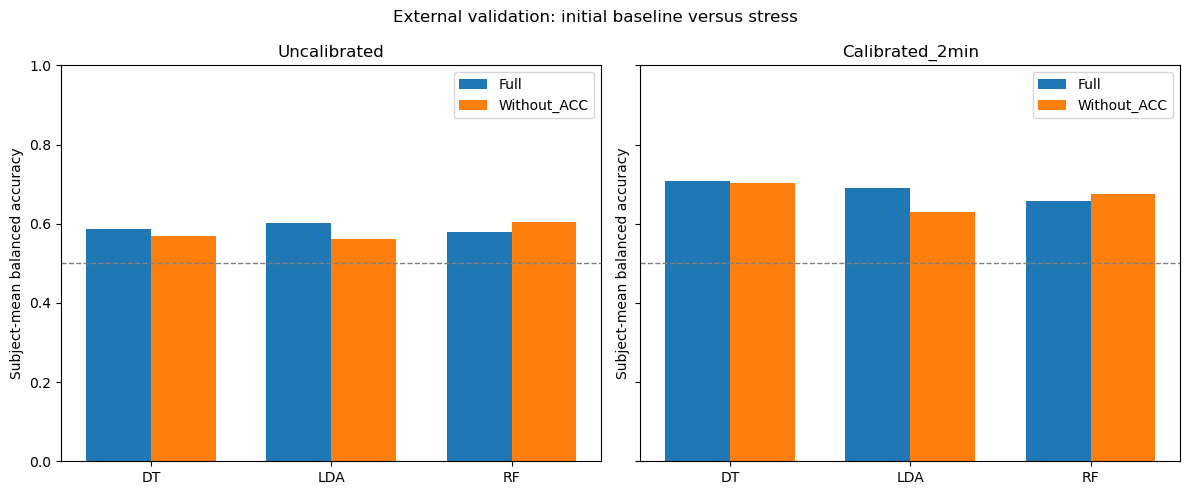


Finished. Results saved to: /Users/chachaen/Desktop/WESAD 2/outputs_external_jackie


In [5]:
def calculate_scores(group):
    if set(group["y"]) != {0, 1}:
        raise ValueError("Both classes are required.")

    tn, fp, fn, tp = confusion_matrix(
        group["y"], group["y_pred"], labels=[0, 1]
    ).ravel()

    return {
        "balanced_accuracy": balanced_accuracy_score(
            group["y"], group["y_pred"]
        ),
        "stress_f1": f1_score(
            group["y"], group["y_pred"], zero_division=0
        ),
        "stress_recall": recall_score(
            group["y"], group["y_pred"], zero_division=0
        ),
        "specificity": tn / (tn + fp),
        "n_nonstress": int(tn + fp),
        "n_stress": int(fn + tp),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }


evaluation_masks = {
    "Initial_baseline_only": (
        (external_predictions["stage"] == "baseline")
        | (external_predictions["y"] == 1)
    ),
    "Baseline_plus_all_rest": pd.Series(
        True, index=external_predictions.index
    ),
    "Baseline_plus_late_rest": (
        (external_predictions["stage"] == "baseline")
        | (external_predictions["y"] == 1)
        | external_predictions["late_rest"]
    ),
}

group_columns = [
    "configuration",
    "feature_set",
    "model",
    "subject_id",
    "version",
]

score_rows = []
excluded_rows = []

for definition, mask in evaluation_masks.items():
    selected = external_predictions.loc[mask].copy()

    for keys, group in selected.groupby(group_columns):
        metadata = dict(zip(group_columns, keys))

        # Do not calculate subject-level BA with only one class.
        if set(group["y"]) != {0, 1}:
            excluded_rows.append({
                "definition": definition,
                **metadata,
                "reason": "One evaluation class is missing.",
            })
            continue

        score_rows.append({
            "definition": definition,
            **metadata,
            **calculate_scores(group),
        })

subject_scores = pd.DataFrame(score_rows)

summary = (
    subject_scores
    .groupby(
        ["definition", "configuration", "feature_set", "model"]
    )
    .agg(
        n_subjects=("subject_id", "nunique"),
        balanced_accuracy_mean=("balanced_accuracy", "mean"),
        balanced_accuracy_sd=("balanced_accuracy", "std"),
        stress_f1_mean=("stress_f1", "mean"),
        stress_recall_mean=("stress_recall", "mean"),
        specificity_mean=("specificity", "mean"),
        n_nonstress=("n_nonstress", "sum"),
        n_stress=("n_stress", "sum"),
    )
    .reset_index()
)

print("PRIMARY: initial baseline versus stress")
display(
    summary.loc[
        summary["definition"] == "Initial_baseline_only"
    ].round(3)
)

print("\nSUPPLEMENTARY: including recovery rest")
display(
    summary.loc[
        summary["definition"] != "Initial_baseline_only"
    ].round(3)
)

# Compare definitions using exactly the same participants.
common_subjects = set(
    subject_scores.loc[
        subject_scores["definition"] == "Initial_baseline_only",
        "subject_id",
    ]
)

common_scores = subject_scores.loc[
    subject_scores["subject_id"].isin(common_subjects)
].copy()

common_comparison = (
    common_scores
    .groupby(
        ["configuration", "feature_set", "model", "definition"]
    )["balanced_accuracy"]
    .mean()
    .unstack("definition")
    .reset_index()
)

print(
    "\nRest-definition comparison using the same",
    len(common_subjects),
    "participants:",
)
display(common_comparison.round(3))

print("\nExcluded from initial-baseline evaluation:")
print(
    sorted(
        set(external_predictions["subject_id"])
        - common_subjects
    )
)

# Report protocol versions separately.
version_summary = (
    subject_scores
    .groupby(
        [
            "definition", "configuration",
            "feature_set", "model", "version",
        ]
    )
    .agg(
        n_subjects=("subject_id", "nunique"),
        balanced_accuracy_mean=("balanced_accuracy", "mean"),
        stress_recall_mean=("stress_recall", "mean"),
        specificity_mean=("specificity", "mean"),
    )
    .reset_index()
)

# Each stage has one label, so use correct fraction rather than BA.
stage_results = (
    external_predictions
    .assign(
        correct=(
            external_predictions["y"]
            == external_predictions["y_pred"]
        )
    )
    .groupby(
        ["configuration", "feature_set", "model", "version", "stage"]
    )
    .agg(
        n_windows=("correct", "size"),
        correct_fraction=("correct", "mean"),
    )
    .reset_index()
)

print("\nStage-specific correct classification: Full models")
display(
    stage_results.loc[
        stage_results["feature_set"] == "Full"
    ].round(3)
)

subject_scores.to_csv(
    OUTPUT_DIR / "external_subject_scores.csv", index=False
)
summary.to_csv(
    OUTPUT_DIR / "external_summary.csv", index=False
)
common_comparison.to_csv(
    OUTPUT_DIR / "rest_definition_common_subjects.csv", index=False
)
version_summary.to_csv(
    OUTPUT_DIR / "results_by_protocol_version.csv", index=False
)
stage_results.to_csv(
    OUTPUT_DIR / "stage_results.csv", index=False
)
pd.DataFrame(excluded_rows).to_csv(
    OUTPUT_DIR / "evaluation_exclusions.csv", index=False
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, configuration in zip(
    axes, ["Uncalibrated", "Calibrated_2min"]
):
    selected = summary.loc[
        (summary["definition"] == "Initial_baseline_only")
        & (summary["configuration"] == configuration)
    ]

    for offset, feature_set in [
        (-0.18, "Full"),
        (0.18, "Without_ACC"),
    ]:
        values = (
            selected.loc[selected["feature_set"] == feature_set]
            .set_index("model")
            .reindex(["DT", "LDA", "RF"])
        )

        ax.bar(
            np.arange(3) + offset,
            values["balanced_accuracy_mean"],
            width=0.36,
            label=feature_set,
        )

    ax.set_xticks(np.arange(3), ["DT", "LDA", "RF"])
    ax.set_ylim(0, 1)
    ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
    ax.set_title(configuration)
    ax.set_ylabel("Subject-mean balanced accuracy")
    ax.legend()

fig.suptitle(
    "External validation: initial baseline versus stress"
)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "external_primary_results.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

manifest = {
    "training_dataset": "WESAD",
    "testing_dataset": "PhysioNet wearable-device-dataset 1.0.1",
    "window_seconds": WINDOW_SECONDS,
    "calibration_seconds": 120,
    "stress_stages": ["stroop", "tmct"],
    "v2_baseline_assumption_seconds": V2_BASELINE_SECONDS,
    "stage_overrides": STAGE_OVERRIDES,
    "excluded_subjects": EXCLUDED_SUBJECTS,
    "packages": {
        name: importlib.metadata.version(name)
        for name in [
            "numpy", "pandas", "scipy",
            "scikit-learn", "neurokit2",
        ]
    },
    "interpretation": (
        "Exploratory external validation. Verify event boundaries "
        "and the V2 baseline assumption before final reporting. "
        "Initial-baseline evaluation contains few negative windows."
    ),
}

(OUTPUT_DIR / "run_manifest.json").write_text(
    json.dumps(manifest, indent=2)
)

print("\nFinished. Results saved to:", OUTPUT_DIR)

In [6]:
import inspect
import scipy
import numpy as np
import pandas as pd

from scipy.stats import wilcoxon, PermutationMethod

# Use existing subject-level external evaluation scores.
analysis_scores = subject_scores.loc[
    (subject_scores["definition"] == "Initial_baseline_only")
    & (subject_scores["feature_set"] == "Full")
    & subject_scores["configuration"].isin(
        ["Uncalibrated", "Calibrated_2min"]
    )
].copy()

MODEL_ORDER = ["DT", "LDA", "RF"]
CONFIGURATIONS = ["Uncalibrated", "Calibrated_2min"]

# Each participant must have exactly one score per model and setting.
key_columns = ["model", "subject_id", "configuration"]

if analysis_scores.duplicated(key_columns).any():
    raise ValueError("Duplicate subject-level scores were found.")

# Pivot raises an error rather than silently averaging duplicate rows.
paired_scores = analysis_scores.pivot(
    index=["model", "subject_id"],
    columns="configuration",
    values="balanced_accuracy",
)

if not set(CONFIGURATIONS).issubset(paired_scores.columns):
    raise ValueError("Both calibration settings are required.")

if paired_scores[CONFIGURATIONS].isna().any().any():
    raise ValueError("Some participants are missing paired scores.")

values = paired_scores[CONFIGURATIONS].to_numpy(dtype=float)

if not np.isfinite(values).all():
    raise ValueError("Scores contain NaN or Inf.")

if not ((values >= 0) & (values <= 1)).all():
    raise ValueError("Balanced accuracy must be between 0 and 1.")

# Require the same participants for all three models.
subject_sets = {
    model: set(paired_scores.xs(model, level="model").index)
    for model in MODEL_ORDER
}

if not all(
    subjects == subject_sets["DT"]
    for subjects in subject_sets.values()
):
    raise ValueError("The three models use different participants.")

print("SciPy version:", scipy.__version__)
print("Evaluation: initial baseline versus stress")
print("Feature set: Full")
print("Participants per model:", len(subject_sets["DT"]))


def make_permutation_method(n_nonzero):
    # Exhaustive sign permutations for small samples.
    # Otherwise use reproducible Monte Carlo permutations.
    settings = {
        "n_resamples": (
            np.inf if n_nonzero <= 15 else 99_999
        ),
        "batch": 1000,
    }

    # Support both newer and older SciPy parameter names.
    if "rng" in inspect.signature(PermutationMethod).parameters:
        settings["rng"] = np.random.default_rng(42)
    else:
        settings["random_state"] = 42

    return PermutationMethod(**settings)


results = []

for model in MODEL_ORDER:
    paired = paired_scores.xs(
        model, level="model"
    ).sort_index()

    uncalibrated = paired["Uncalibrated"].to_numpy()
    calibrated = paired["Calibrated_2min"].to_numpy()

    # Positive differences favor calibration.
    difference_pp = 100 * (calibrated - uncalibrated)

    # Remove floating-point noise while preserving score precision.
    ranked_difference_pp = np.round(difference_pp, decimals=8)
    nonzero_difference = ranked_difference_pp[
        ranked_difference_pp != 0
    ]

    if len(nonzero_difference) == 0:
        # Reporting convention: identical observed scores.
        statistic = 0.0
        p_value = 1.0
        calculation = "All paired differences are zero"
    else:
        test = wilcoxon(
            nonzero_difference,
            alternative="two-sided",
            zero_method="wilcox",
            method=make_permutation_method(
                len(nonzero_difference)
            ),
        )
        statistic = float(test.statistic)
        p_value = float(test.pvalue)
        calculation = (
            "Exhaustive permutation"
            if len(nonzero_difference) <= 15
            else "Monte Carlo permutation: 99,999 resamples"
        )

    results.append({
        "model": model,
        "n_subjects": len(paired),
        "n_nonzero": len(nonzero_difference),
        "uncalibrated_BA_mean": uncalibrated.mean(),
        "calibrated_BA_mean": calibrated.mean(),
        "mean_change_pp": difference_pp.mean(),
        "median_change_pp": np.median(difference_pp),
        "n_improved": int((ranked_difference_pp > 0).sum()),
        "n_unchanged": int((ranked_difference_pp == 0).sum()),
        "n_worsened": int((ranked_difference_pp < 0).sum()),
        "wilcoxon_W": statistic,
        "p_raw": p_value,
        "calculation": calculation,
    })

calibration_test_results = pd.DataFrame(results)

# Holm correction across these three model comparisons.
p_values = calibration_test_results["p_raw"].to_numpy()
order = np.argsort(p_values)

adjusted_sorted = np.maximum.accumulate(
    (len(p_values) - np.arange(len(p_values)))
    * p_values[order]
)

adjusted_p_values = np.empty_like(p_values)
adjusted_p_values[order] = np.minimum(adjusted_sorted, 1.0)

calibration_test_results["p_holm"] = adjusted_p_values
calibration_test_results["significant_holm"] = (
    calibration_test_results["p_holm"] < 0.05
)

print("\nCalibration effects and paired statistical tests:")
display(
    calibration_test_results.drop(columns="calculation").round({
        "uncalibrated_BA_mean": 3,
        "calibrated_BA_mean": 3,
        "mean_change_pp": 2,
        "median_change_pp": 2,
        "wilcoxon_W": 2,
        "p_raw": 5,
        "p_holm": 5,
    })
)

print("\nInterpretation:")
for row in calibration_test_results.itertuples(index=False):
    if row.significant_holm:
        conclusion = (
            "Evidence of a paired performance difference "
            "after Holm correction."
        )
    else:
        conclusion = (
            "Insufficient evidence of a paired performance "
            "difference after Holm correction."
        )

    print(
        f"{row.model}: mean change = {row.mean_change_pp:+.2f} pp; "
        f"Holm-adjusted p = {row.p_holm:.5f}. {conclusion}"
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

calibration_test_results.to_csv(
    OUTPUT_DIR / "external_initial_baseline_calibration_tests.csv",
    index=False,
)

paired_scores.reset_index().to_csv(
    OUTPUT_DIR / "external_initial_baseline_calibration_pairs.csv",
    index=False,
)

print("\nSaved statistical results to:", OUTPUT_DIR)

SciPy version: 1.16.3
Evaluation: initial baseline versus stress
Feature set: Full
Participants per model: 29

Calibration effects and paired statistical tests:


,model,n_subjects,n_nonzero,uncalibrated_BA_mean,calibrated_BA_mean,mean_change_pp,median_change_pp,n_improved,n_unchanged,n_worsened,wilcoxon_W,p_raw,p_holm,significant_holm
0,DT,29,21,0.586,0.707,12.17,7.14,15,8,6,57.0,0.04018,0.12054,False
1,LDA,29,21,0.601,0.690,8.91,8.33,15,8,6,72.5,0.13662,0.27324,False
2,RF,29,21,0.579,0.657,7.80,8.33,15,8,6,72.5,0.13882,0.27324,False



Interpretation:
DT: mean change = +12.17 pp; Holm-adjusted p = 0.12054. Insufficient evidence of a paired performance difference after Holm correction.
LDA: mean change = +8.91 pp; Holm-adjusted p = 0.27324. Insufficient evidence of a paired performance difference after Holm correction.
RF: mean change = +7.80 pp; Holm-adjusted p = 0.27324. Insufficient evidence of a paired performance difference after Holm correction.

Saved statistical results to: /Users/chachaen/Desktop/WESAD 2/outputs_external_jackie
